In [93]:
# Implement Polynomial Regression on the California Housing dataset to predict
# median house value based on median income.. Compare polynomial regression results with linear
# regression.
# Tasks:
# ● Load and preprocess the dataset.
# ● Implement polynomial regression of varying degrees.
# ● Compare the polynomial regression models with linear regression using metrics such as MSE and R-squared.
# ● Visualize the polynomial fit.

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split

In [95]:
data = fetch_california_housing(as_frame = True)
data = data.frame
data

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [96]:
x = data[['MedInc']].values
y = data['MedHouseVal']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [97]:
# Linear Regression
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)
linear_pred = linear_model.predict(x_test)
results = []
results.append(['Linear Regression',mean_squared_error(y_test,linear_pred),r2_score(y_test,linear_pred)])

In [98]:
# Polynomial Regression
for degrees in [2,3,5]:
    poly = PolynomialFeatures(degree = degrees)
    x_train_poly = poly.fit_transform(x_train)
    x_test_poly = poly.transform(x_test)
    model = LinearRegression()
    model.fit(x_train_poly,y_train)
    pred = model.predict(x_test_poly)
    results.append([f"Polynomial Regression: Degree {degrees}",mean_squared_error(y_test,pred),r2_score(y_test,pred)])
    

In [99]:
comparison = pd.DataFrame(results,columns = ["Model","MSE","R2 Score"])
comparison

,Model,MSE,R2 Score
0,Linear Regression,0.709116,0.458859
1,Polynomial Regression: Degree 2,0.703273,0.463318
2,Polynomial Regression: Degree 3,0.698296,0.467116
3,Polynomial Regression: Degree 5,0.698716,0.466796


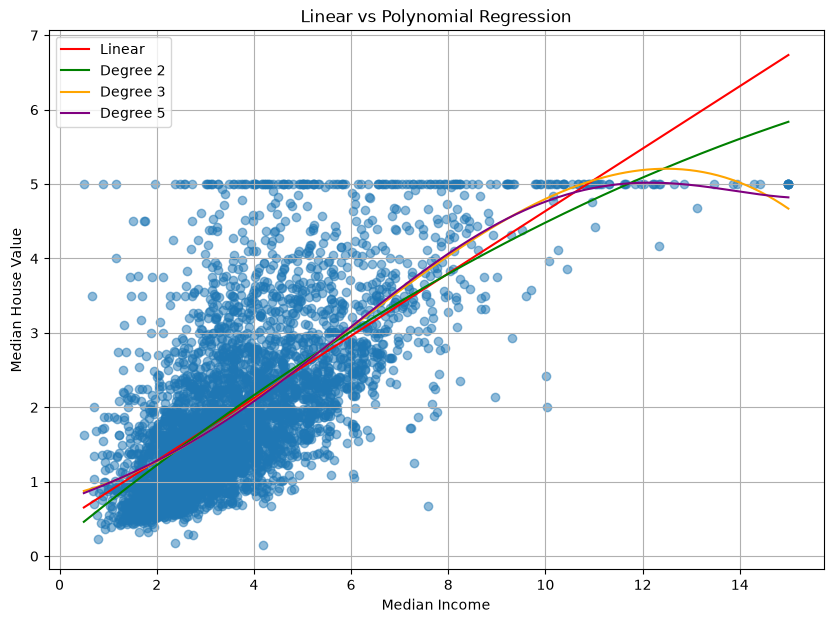

In [100]:
# Plot
x_curve = np.linspace(x_test.min(),x_test.max(),500).reshape(-1,1)
plt.figure(figsize=(10,7))
plt.scatter(x_test,y_test,alpha = 0.5)
linear_pred_curve = linear_model.predict(x_curve)
plt.plot(x_curve,linear_pred_curve,color = 'red',label = 'Linear')
colors = ["green", "orange", "purple"]
for degrees,color in zip([2,3,5],colors):
    poly = PolynomialFeatures(degree = degrees)
    x_train_poly = poly.fit_transform(x_train)
    x_test_poly = poly.transform(x_curve)
    model = LinearRegression()
    model.fit(x_train_poly,y_train)
    pred = model.predict(x_test_poly)
    plt.plot(x_curve,pred,color = color,label=f"Degree {degrees}")
plt.grid()
plt.legend()
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Linear vs Polynomial Regression")
plt.show()
